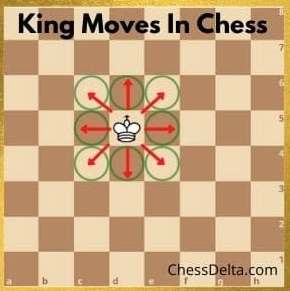

In [ ]:
import numpy
A = numpy.ones((8,8));
S = numpy.zeros((A.size, A.size))
for m in range(A.shape[0]):
  for n in range(A.shape[1]):
    for x in [-1, 0, 1]:
      for y in [-1, 0 ,1]:
        if x == 0 and y == 0:
          continue
        try:
          A[m + x, n + y];
          S[numpy.ravel_multi_index([m, n], A.shape), numpy.ravel_multi_index([m+x, n +y], A.shape)] = 1
        except:
          continue


In [ ]:
numpy.where(S[9,:] != 0)

(array([ 0,  1,  2,  8, 10, 16, 17, 18]),)

## Matriz de Estados Finitos

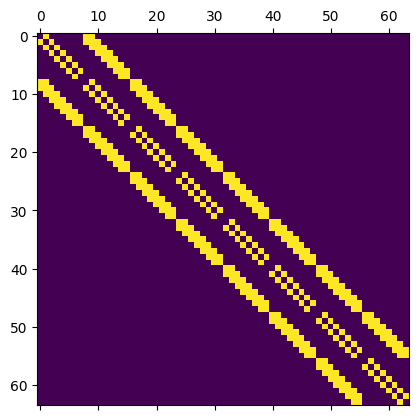

In [ ]:
from matplotlib import pyplot

pyplot.matshow(S)

pyplot.show()

## Matriz de Distancias

In [ ]:
import numpy

D = numpy.zeros((A.size, A.size));

d_base = 0.3; # 30 centimetros de un azulejo

for n in range(S.shape[0]):
  for m in range(S.shape[1]):
    if n == m:
      continue
    i, j = numpy.unravel_index(n, A.shape); # convertir el indice lineal en un indice de 2d
    k, l = numpy.unravel_index(m, A.shape)
    D[n,m] = d_base * numpy.linalg.norm( numpy.asarray( [i-k , j -l]) );



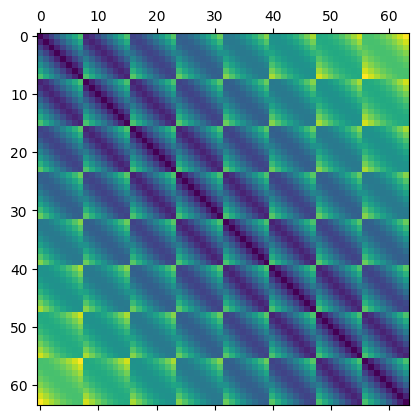

In [ ]:
from matplotlib import pyplot

pyplot.matshow(D)

pyplot.show()

In [ ]:
numpy.sum( numpy.diag(D))

np.float64(0.0)

## Matriz de Probabilidad

In [ ]:
import numpy

P = S.copy();

for i in range(S.shape[0]):
  s_ = numpy.sum( S[i,:]  ); # integral
  P[i, :] /= s_ # porque es una distribucion uniforme





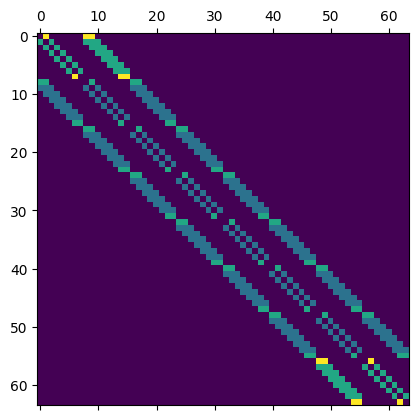

In [ ]:
from matplotlib import pyplot

pyplot.matshow(P)

pyplot.show()

## Movimiento de los Agentes

Definir una ruta $r_1 = \lbrace s_0, s_1, s_2, ... s_6, s_{11} \rbrace$.

In [ ]:
r_1 = numpy.asarray([0,1,2,3,4,5,6,7,15], dtype = numpy.int32);

Revisar que la ruta $r_1$ es una ruta valida.

In [ ]:

Valida = True

for i in range(len(r_1)-1):
  if S[r_1[i], r_1[i+1] ] == 0:
    Valida = False
    break



print(Valida)

True


## Probabilidad de la ruta

In [ ]:
r_1 = numpy.asarray([0,1,2,3,4,5,6,7,15]);

In [ ]:
#

#p_ = 1; # opcion 1 acumulando
p_ = []; # opcion 2 guardar todas la probabilidad de la ruta

for i in range(len(r_1)-1):
  if S[r_1[i], r_1[i+1] ] == 0:
    break
  #p_ *= P[ r_1[i] , r_1[i+1] ]
  p_.append( P[ r_1[i] , r_1[i+1] ])

p_ = - numpy.log( numpy.prod( numpy.asarray(p_) ))

print(p_)


11.853852051940821


## Movimiento de Agentes

Mover un alfil

In [ ]:
input("Tipo de Ruta [ZZ, A, S]")



In [ ]:

r_2 = [];

for i in range(8):
  r_2.append(int( numpy.ravel_multi_index([i, i], A.shape) ))

print(r_2)



[0, 9, 18, 27, 36, 45, 54, 63]


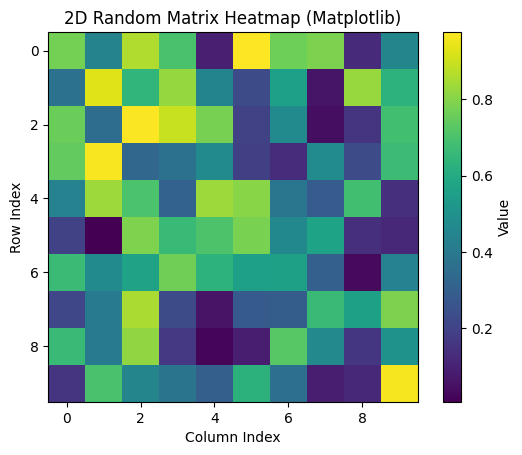

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a 10x10 random matrix (floats between 0 and 1)
rng = np.random.default_rng(seed=42)
matrix = rng.random((10, 10))

# 2. Plot the heatmap
plt.imshow(matrix, cmap="viridis", interpolation="nearest")
plt.colorbar(label="Value")
plt.title("2D Random Matrix Heatmap (Matplotlib)")
plt.xlabel("Column Index")
plt.ylabel("Row Index")
plt.show()
